# 01 — Exploratory Data Analysis

**Objective.** Understand the bank churn dataset before modelling: schema, target
balance, feature distributions, missingness and the segments most associated with
churn. 

**Decisions this notebook justifies:** which columns are usable features, and which
identifiers must be dropped to avoid leakage.

In [13]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
from pathlib import Path
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists()), Path.cwd())
RAW = ROOT / "data" / "raw" / "binaryclassificationwithabankchurndataset"
PROC = ROOT / "data" / "processed"
MODELS = ROOT / "models"
FIG = MODELS / "figures"
for d in (PROC, FIG):
    d.mkdir(parents=True, exist_ok=True)
print("project root:", ROOT)

project root: /home/sabina/portfolio/creditscoring


In [14]:
df = pd.read_csv(RAW / "train.csv")
print("Train shape:", df.shape)
print("Test shape :", pd.read_csv(RAW / "test.csv").shape)
display(df.head())

Train shape: (15000, 14)
Test shape : (10000, 13)


,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,0,15702656.0,Nwora,567.0,France,Male,33.0,9.0,0.0,2.0,1.0,0.0,156792.89,0.0
1,1,15647965.0,Yevdokimova,628.0,France,Female,38.0,3.0,0.0,1.0,1.0,1.0,51987.99,1.0
2,2,15798834.0,Ch'iu,635.0,France,Female,29.0,3.0,0.0,2.0,1.0,1.0,113079.19,0.0
3,3,15672056.0,Hsia,681.0,France,Male,28.0,6.0,0.0,2.0,1.0,0.0,14081.64,0.0
4,4,15759537.0,Okwudilichukwu,587.0,France,Female,27.0,5.0,0.0,2.0,1.0,0.0,158958.90,0.0


In [15]:
print("=== dtypes ===")
print(df.dtypes.to_string())
print("\n=== missing values ===")
print(df.isna().sum().to_string())
print("\nDuplicate rows:", df.duplicated().sum())
print("CustomerId unique:", df["CustomerId"].nunique(), "of", len(df))

=== dtypes ===
id                   int64
CustomerId         float64
Surname                str
CreditScore        float64
Geography              str
Gender                 str
Age                float64
Tenure             float64
Balance            float64
NumOfProducts      float64
HasCrCard          float64
IsActiveMember     float64
EstimatedSalary    float64
Exited             float64

=== missing values ===
id                 0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0

Duplicate rows: 0
CustomerId unique: 6306 of 15000


## Target balance

`Exited = 1` means the customer left the bank (churn). The classes are imbalanced
(~20% positive), so accuracy alone will be misleading — we will track churn recall,
PR-AUC and ROC-AUC later.

,count,percent
Exited,,
0.0,12023,80.15
1.0,2977,19.85


/tmp/ipykernel_210210/506526383.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=summary.index.astype(str), y=summary["percent"], ax=ax, palette="Blues_d")


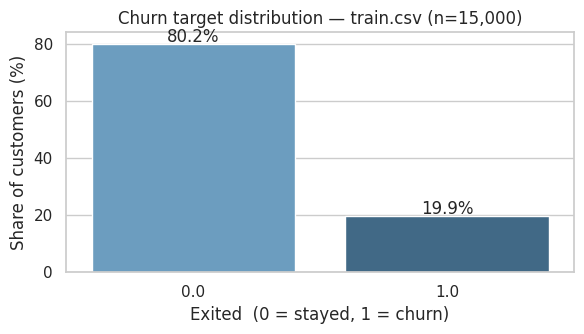

In [16]:
target = "Exited"
counts = df[target].value_counts().sort_index()
pct = (df[target].value_counts(normalize=True).sort_index() * 100).round(2)
summary = pd.DataFrame({"count": counts, "percent": pct})
display(summary)
fig, ax = plt.subplots(figsize=(6, 3.5))
sns.barplot(x=summary.index.astype(str), y=summary["percent"], ax=ax, palette="Blues_d")
ax.set_title("Churn target distribution — train.csv (n=15,000)")
ax.set_xlabel("Exited  (0 = stayed, 1 = churn)")
ax.set_ylabel("Share of customers (%)")
for i, v in enumerate(summary["percent"]):
    ax.text(i, v + 0.6, f"{v:.1f}%", ha="center")
plt.tight_layout(); plt.show()

Numeric feature distribution

,count,mean,std,min,25%,50%,75%,max
CreditScore,15000.0,657.86,72.68,431.00,602.00,661.00,707.00,850.00
Age,15000.0,37.71,8.14,18.00,32.00,37.00,42.00,72.00
Tenure,15000.0,5.02,2.79,0.00,3.00,5.00,7.00,10.00
Balance,15000.0,42338.11,59703.05,0.00,0.00,0.00,109636.34,187911.55
NumOfProducts,15000.0,1.59,0.53,1.00,1.00,2.00,2.00,5.00
HasCrCard,15000.0,0.78,0.41,0.00,1.00,1.00,1.00,1.00
IsActiveMember,15000.0,0.50,0.50,0.00,0.00,0.00,1.00,1.00
EstimatedSalary,15000.0,116944.06,46047.49,11.58,82644.33,122449.42,155703.02,885120.79


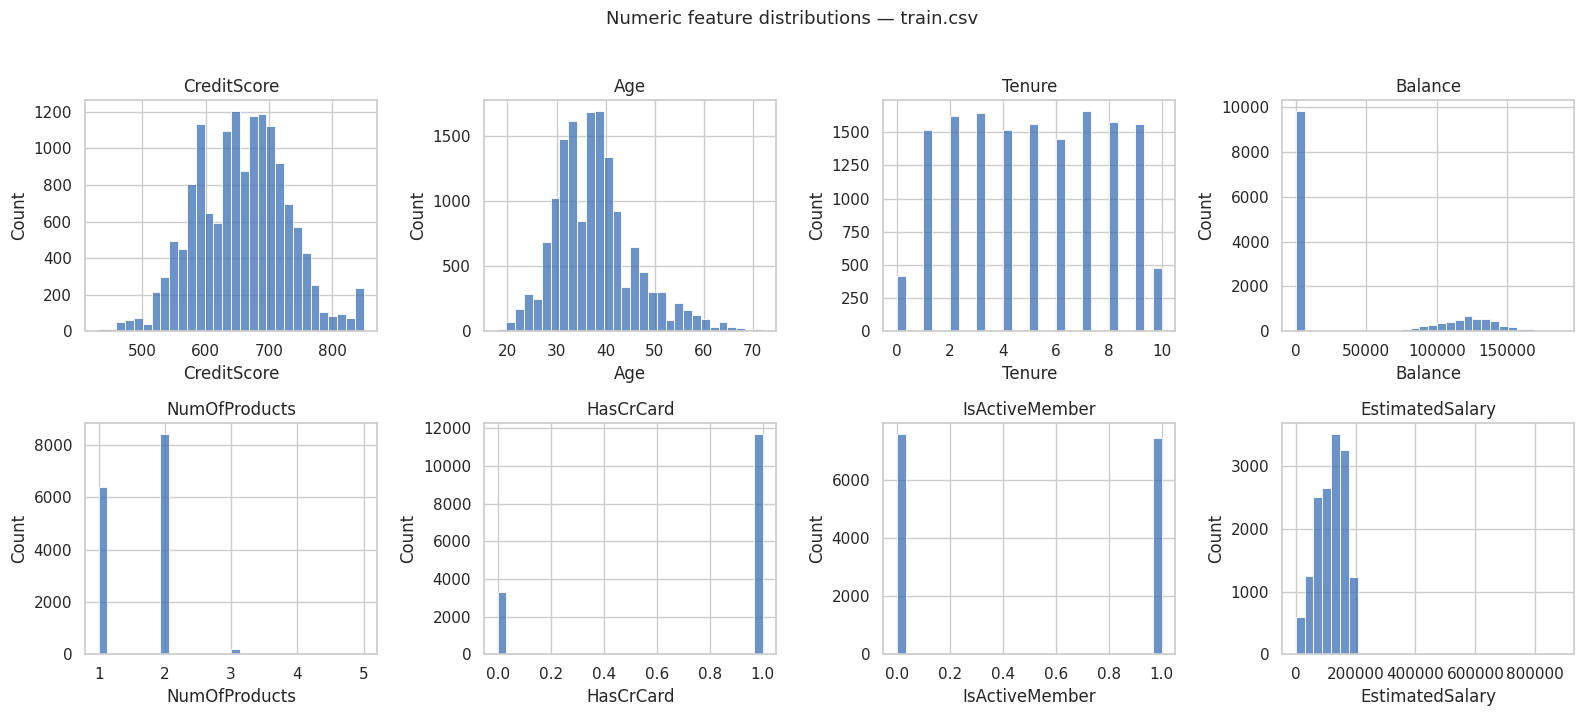

In [17]:
num_cols = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts",
            "HasCrCard", "IsActiveMember", "EstimatedSalary"]
display(df[num_cols].describe().T.round(2))
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(df[c], bins=30, ax=ax, color="#3b6fb6")
    ax.set_title(c); ax.set_xlabel(c)
plt.suptitle("Numeric feature distributions — train.csv", y=1.02, fontsize=13)
plt.tight_layout(); plt.show()

## Churn rate by segment

These plots show where churn concentrates and motivate keeping Geography, Gender,
NumOfProducts and IsActiveMember as features.

/tmp/ipykernel_210210/1338812800.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rates.index.astype(str), y=rates.values, ax=ax, palette="Blues_d")
/tmp/ipykernel_210210/1338812800.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rates.index.astype(str), y=rates.values, ax=ax, palette="Blues_d")
/tmp/ipykernel_210210/1338812800.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rates.index.astype(str), y=rates.values, ax=ax, palette="Blues_d")
/tmp/ipykernel_210210/1338812800.py:4: FutureWarning: 

Passing `palette` without ass

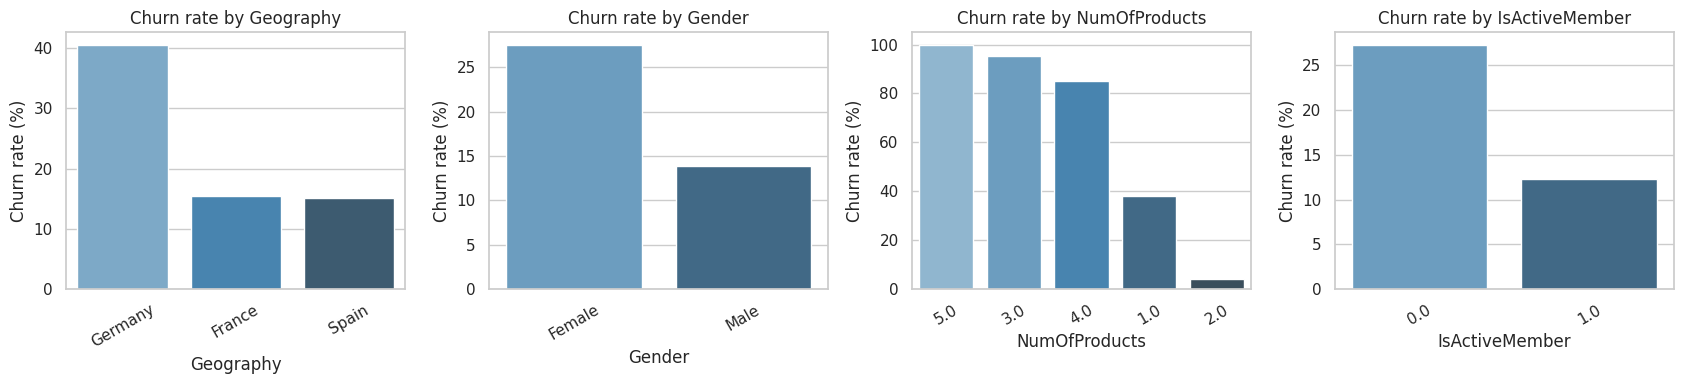

In [18]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, c in zip(axes, ["Geography", "Gender", "NumOfProducts", "IsActiveMember"]):
    rates = df.groupby(c)[target].mean().mul(100).sort_values(ascending=False)
    sns.barplot(x=rates.index.astype(str), y=rates.values, ax=ax, palette="Blues_d")
    ax.set_title(f"Churn rate by {c}")
    ax.set_xlabel(c); ax.set_ylabel("Churn rate (%)")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

Correlation structure

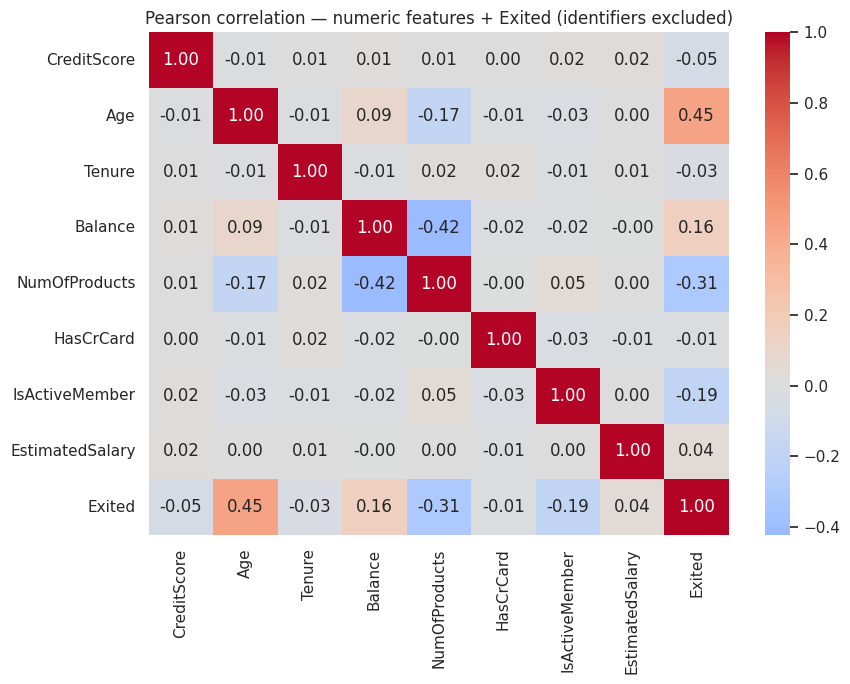

In [19]:
corr = df.drop(columns=["id", "CustomerId", "Surname"]).corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Pearson correlation — numeric features + Exited (identifiers excluded)")
plt.tight_layout(); plt.show()

# 02 — Preprocessing & Splitting

**Objective.** Create a stratified train/validation split from `train.csv` and define
preprocessing that is fitted on **training data only**. The split and a demonstration
of the fitted `ColumnTransformer` are saved for the next notebooks.

No preprocessing is fitted on `test.csv`: it is unlabelled and reserved for the final
submission.

In [20]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from pathlib import Path
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists()), Path.cwd())
RAW = ROOT / "data" / "raw" / "binaryclassificationwithabankchurndataset"
PROC = ROOT / "data" / "processed"
MODELS = ROOT / "models"
FIG = MODELS / "figures"
for d in (PROC, FIG):
    d.mkdir(parents=True, exist_ok=True)
print("project root:", ROOT)

project root: /home/sabina/portfolio/creditscoring


In [21]:
DROP = ["id", "CustomerId", "Surname"]
df = pd.read_csv(RAW / "train.csv").drop(columns=DROP)
X = df.drop(columns=["Exited"])
y = df["Exited"]
print("Features:", X.columns.tolist())
print("Class balance:", y.value_counts(normalize=True).round(4).to_dict())

Features: ['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']
Class balance: {0.0: 0.8015, 1.0: 0.1985}


In [22]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
train = X_train.copy(); train["Exited"] = y_train
val = X_val.copy();   val["Exited"] = y_val
train.to_csv(PROC / "train.csv", index=False)
val.to_csv(PROC / "val.csv", index=False)
print(f"Train: {X_train.shape[0]:,} rows | churn {y_train.mean():.1%}")
print(f"Val  : {X_val.shape[0]:,} rows | churn {y_val.mean():.1%}")

Train: 12,000 rows | churn 19.9%
Val  : 3,000 rows | churn 19.8%


## Preprocessor (demonstration, fitted on train only)

Numeric → median imputation + standardisation. Categorical → most-frequent
imputation + one-hot encoding with `handle_unknown='ignore'` so unseen validation /
inference categories never crash scoring. Notebook 03 rebuilds the same transformer
inside each candidate model's `Pipeline`, guaranteeing identical transforms.

In [23]:
num = X.select_dtypes(include=np.number).columns.tolist()
cat = X.select_dtypes(exclude=np.number).columns.tolist()
print("Numeric:", num)
print("Categorical:", cat)

def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]), num),
        ("cat", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), cat),
    ])

prep = make_preprocessor()
Xt = prep.fit_transform(X_train)
print("Transformed train matrix:", Xt.shape)
print("Zero-variance check — all finite:", np.isfinite(Xt).all())

Numeric: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']
Categorical: ['Geography', 'Gender']
Transformed train matrix: (12000, 13)
Zero-variance check — all finite: True


**Outcome.** A reproducible 80/20 stratified split is saved to `data/processed/`,
and the preprocessing contract is fixed (train-only fitting, unknown-safe encoding).
**Next:** 03_training — benchmark candidates under cross-validation.

# 03 — Model Training & Selection

**Objective.** Benchmark a baseline plus a broad set of classifiers (linear, trees,
bagging, and four boosting libraries) under identical 5-fold stratified
cross-validation, then fit the winner on the full training split and persist a
single `Pipeline` (preprocessor + model) for serving.

Selection metric: **ROC-AUC**, with **churn recall** reported alongside as the
primary risk criterion. PR-AUC and F1 complete the picture for the imbalanced target.

In [24]:
import time, joblib, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from pathlib import Path
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists()), Path.cwd())
RAW = ROOT / "data" / "raw" / "binaryclassificationwithabankchurndataset"
PROC = ROOT / "data" / "processed"
MODELS = ROOT / "models"
FIG = MODELS / "figures"
for d in (PROC, FIG):
    d.mkdir(parents=True, exist_ok=True)
print("project root:", ROOT)

project root: /home/sabina/portfolio/creditscoring


In [25]:
train = pd.read_csv(PROC / "train.csv")
X = train.drop(columns=["Exited"]); y = train["Exited"]
num = X.select_dtypes(include=np.number).columns.tolist()
cat = X.select_dtypes(exclude=np.number).columns.tolist()

def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), num),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat),
    ])

pos_weight = (y == 0).sum() / (y == 1).sum()
# Uniform preprocessor (one-hot for categoricals) is shared by every candidate.
# CatBoost still works on the numeric matrix; allow_writing_files=False prevents
# stray catboost_info/ scratch directories.
models = {
    "Dummy (prior)": DummyClassifier(strategy="prior"),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=None,
                      class_weight="balanced_subsample", random_state=42, n_jobs=-1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, class_weight="balanced_subsample",
                      random_state=42, n_jobs=-1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(max_iter=200, learning_rate=0.06,
                      max_leaf_nodes=15, l2_regularization=1.0, random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=300, num_leaves=15, learning_rate=0.05,
                      class_weight="balanced", verbose=-1, random_state=42, n_jobs=-1),
    "CatBoost": CatBoostClassifier(iterations=300, depth=5, learning_rate=0.05,
                      l2_leaf_reg=5, auto_class_weights="Balanced",
                      allow_writing_files=False, verbose=False,
                      random_state=42, thread_count=2),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                      subsample=0.8, colsample_bytree=0.8, scale_pos_weight=pos_weight,
                      eval_metric="logloss", random_state=42, n_jobs=-1, verbosity=0),
}
print("Models:", list(models))

Models: ['Dummy (prior)', 'Logistic Regression', 'Decision Tree', 'Random Forest', 'Extra Trees', 'Hist Gradient Boosting', 'LightGBM', 'CatBoost', 'XGBoost']


In [26]:
from sklearn.model_selection import StratifiedKFold, cross_validate
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision",
           "f1": "f1", "recall": "recall"}
rows = []
for name, est in models.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("clf", est)])
    t0 = time.time()
    res = cross_validate(pipe, X, y, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({
        "model": name,
        "roc_auc": res["test_roc_auc"].mean(),
        "pr_auc": res["test_pr_auc"].mean(),
        "f1": res["test_f1"].mean(),
        "churn_recall": res["test_recall"].mean(),
        "fit_s": time.time() - t0,
    })
    print(f"{name:20s} done in {rows[-1]['fit_s']:.1f}s")

leaderboard = pd.DataFrame(rows).sort_values(
    ["roc_auc", "churn_recall"], ascending=False
).reset_index(drop=True)
leaderboard.round(4)

Dummy (prior)        done in 3.5s
Logistic Regression  done in 2.7s
Decision Tree        done in 0.6s
Random Forest        done in 70.0s
Extra Trees          done in 2.6s
Hist Gradient Boosting done in 1.0s
LightGBM             done in 617.3s
CatBoost             done in 1.7s
XGBoost              done in 2.3s


,model,roc_auc,pr_auc,f1,churn_recall,fit_s
0,CatBoost,0.9321,0.8095,0.7076,0.8451,1.7475
1,XGBoost,0.9301,0.8039,0.7080,0.8388,2.3026
2,Hist Gradient Boosting,0.9297,0.8026,0.7107,0.6616,1.0371
3,LightGBM,0.9279,0.7991,0.7091,0.8329,617.3359
4,Random Forest,0.9227,0.7768,0.6768,0.5987,69.9507
5,Extra Trees,0.9190,0.7675,0.6727,0.5982,2.6492
6,Decision Tree,0.9116,0.7590,0.6855,0.8426,0.5873
7,Logistic Regression,0.8838,0.6924,0.6393,0.8010,2.7343
8,Dummy (prior),0.5000,0.1985,0.0000,0.0000,3.4946


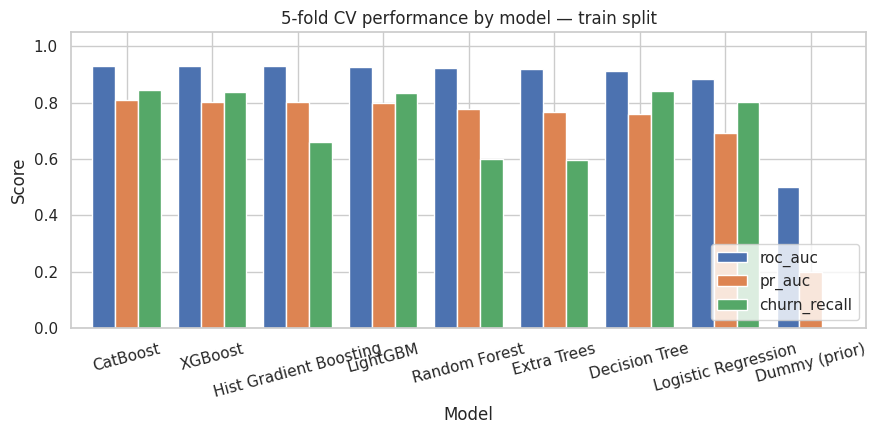

In [27]:
fig, ax = plt.subplots(figsize=(9, 4.5))
plot_df = leaderboard.set_index("model")[["roc_auc", "pr_auc", "churn_recall"]]
plot_df.plot(kind="bar", ax=ax, width=0.8)
ax.set_title("5-fold CV performance by model — train split")
ax.set_xlabel("Model"); ax.set_ylabel("Score")
ax.set_ylim(0, 1.05); ax.legend(loc="lower right")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

## Fit and persist the winner

The top model (excluding the dummy baseline) is refit on the entire training split.
Saving the **whole pipeline** — not just the estimator — locks preprocessing to the
exact fitted state used in training, eliminating train/serving skew.

In [28]:
best_name = leaderboard.loc[leaderboard["model"] != "Dummy (prior)", "model"].iloc[0]
best_est = models[best_name]
final_pipe = Pipeline([("prep", make_preprocessor()), ("clf", best_est)])
final_pipe.fit(X, y)
joblib.dump(final_pipe, MODELS / "pipeline.pkl")
leaderboard.to_csv(MODELS / "leaderboard.csv", index=False)
print("Selected model:", best_name)
print("Saved:", MODELS / "pipeline.pkl")

Selected model: CatBoost
Saved: /home/sabina/portfolio/creditscoring/models/pipeline.pkl


**Outcome.** Cross-validated leaderboard saved to `models/leaderboard.csv`; winning
pipeline saved to `models/pipeline.pkl`.

**Next:** 04_evaluation — a single held-out evaluation, explainability, and the
unlabelled test-set submission.

# 04 — Final Evaluation, Explainability & Submission

**Objective.** Evaluate the saved pipeline **once** on the untouched validation
split, explain its predictions, persist metrics/figures for the Streamlit UI, and
produce a submission for the unlabelled `test.csv`.

No metric here is claimed on `test.csv` — it has no labels.

In [29]:
import json, joblib, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
    average_precision_score, f1_score, recall_score, precision_score, accuracy_score,
    roc_curve, precision_recall_curve)
from sklearn.inspection import permutation_importance
from pathlib import Path
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists()), Path.cwd())
RAW = ROOT / "data" / "raw" / "binaryclassificationwithabankchurndataset"
PROC = ROOT / "data" / "processed"
MODELS = ROOT / "models"
FIG = MODELS / "figures"
for d in (PROC, FIG):
    d.mkdir(parents=True, exist_ok=True)
print("project root:", ROOT)

project root: /home/sabina/portfolio/creditscoring


In [30]:
pipe = joblib.load(MODELS / "pipeline.pkl")
val = pd.read_csv(PROC / "val.csv")
Xv = val.drop(columns=["Exited"]); yv = val["Exited"].astype(int)

THRESHOLD = 0.50
proba = pipe.predict_proba(Xv)[:, 1]
pred = (proba >= THRESHOLD).astype(int)

metrics = {
    "accuracy": accuracy_score(yv, pred),
    "precision": precision_score(yv, pred, zero_division=0),
    "recall_churn": recall_score(yv, pred),
    "f1": f1_score(yv, pred),
    "roc_auc": roc_auc_score(yv, proba),
    "pr_auc": average_precision_score(yv, proba),
}
print(pd.Series(metrics).round(4).to_string())
print("\n", classification_report(yv, pred, target_names=["stayed", "churn"]))

accuracy        0.8600
precision       0.6033
recall_churn    0.8588
f1              0.7087
roc_auc         0.9338
pr_auc          0.8264

               precision    recall  f1-score   support

      stayed       0.96      0.86      0.91      2405
       churn       0.60      0.86      0.71       595

    accuracy                           0.86      3000
   macro avg       0.78      0.86      0.81      3000
weighted avg       0.89      0.86      0.87      3000



Confusion Matrix, ROC and PR curves

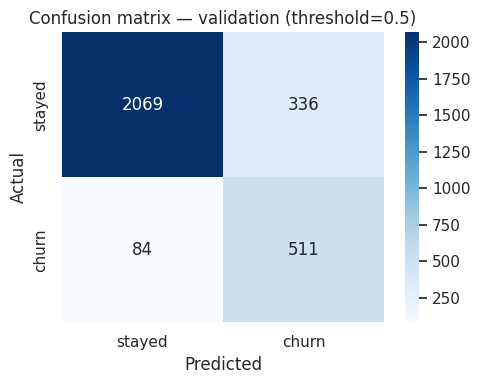

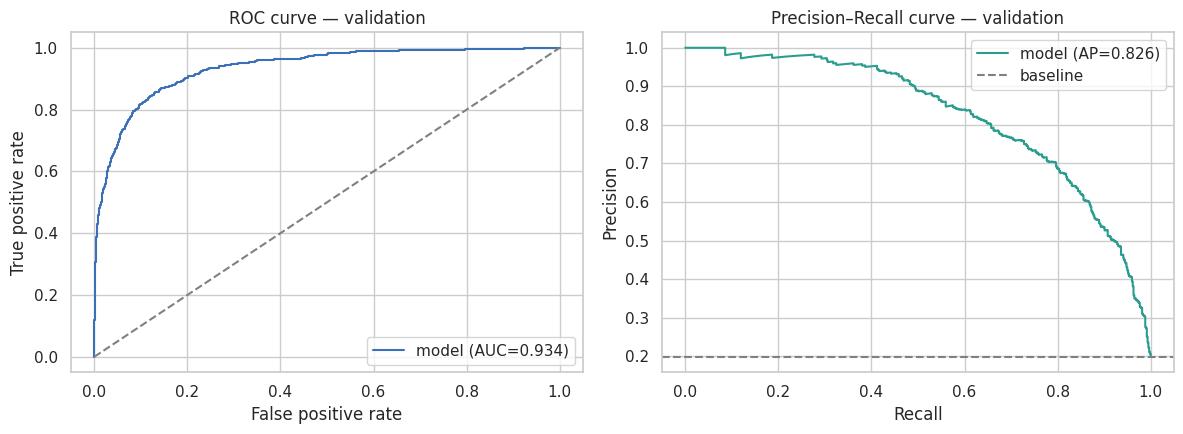

In [31]:
cm = confusion_matrix(yv, pred)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
            xticklabels=["stayed", "churn"], yticklabels=["stayed", "churn"])
ax.set_title(f"Confusion matrix — validation (threshold={THRESHOLD})")
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.savefig(FIG / "confusion_matrix.png", dpi=120); plt.show()

fpr, tpr, _ = roc_curve(yv, proba)
pr, rc, _ = precision_recall_curve(yv, proba)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(fpr, tpr, color="#3b6fb6", label=f"model (AUC={metrics['roc_auc']:.3f})")
axes[0].plot([0,1], [0,1], "--", color="grey"); axes[0].set_title("ROC curve — validation")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate"); axes[0].legend()
axes[1].plot(rc, pr, color="#2a9d8f", label=f"model (AP={metrics['pr_auc']:.3f})")
axes[1].axhline(yv.mean(), ls="--", color="grey", label="baseline")
axes[1].set_title("Precision–Recall curve — validation")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].legend()
plt.tight_layout(); plt.savefig(FIG / "roc_pr.png", dpi=120); plt.show()

## Explainability — permutation importance

Model-agnostic importance measured as the drop in validation ROC-AUC when a single
original feature is shuffled. Larger drops mean the model relies more on that feature.

,feature,importance,std
6,NumOfProducts,0.1389,0.0044
3,Age,0.1014,0.0060
5,Balance,0.0291,0.0024
8,IsActiveMember,0.0175,0.0021
1,Geography,0.0145,0.0011
2,Gender,0.0070,0.0014
0,CreditScore,0.0031,0.0002
9,EstimatedSalary,0.0008,0.0007
4,Tenure,0.0003,0.0003
7,HasCrCard,-0.0001,0.0002


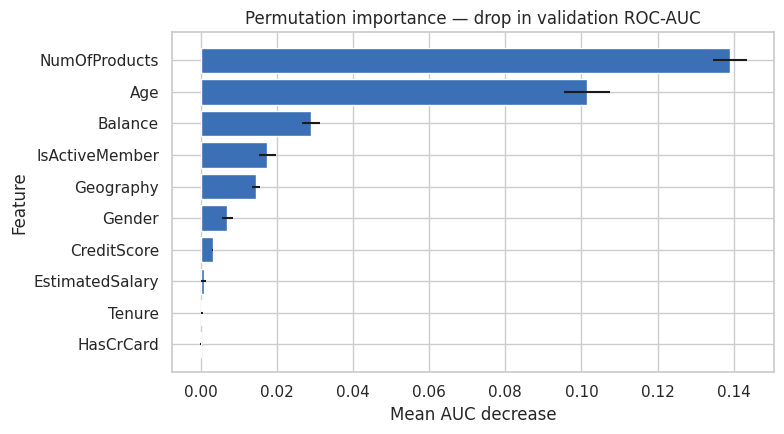

In [32]:
result = permutation_importance(pipe, Xv, yv, scoring="roc_auc",
                                n_repeats=8, random_state=42, n_jobs=-1)
imp = pd.DataFrame({"feature": Xv.columns,
                    "importance": result.importances_mean,
                    "std": result.importances_std}).sort_values("importance", ascending=False)
display(imp.round(4))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(imp["feature"][::-1], imp["importance"][::-1],
        xerr=imp["std"][::-1], color="#3b6fb6")
ax.set_title("Permutation importance — drop in validation ROC-AUC")
ax.set_xlabel("Mean AUC decrease"); ax.set_ylabel("Feature")
plt.tight_layout(); plt.savefig(FIG / "importance.png", dpi=120); plt.show()

## Persist metadata for the UI

All numbers consumed by the Streamlit app come from this file — the UI never
hardcodes metrics.

In [33]:
metadata = {
    "feature_order": Xv.columns.tolist(),
    "threshold": THRESHOLD,
    "train_rows": int(len(pd.read_csv(PROC / "train.csv"))),
    "val_rows": int(len(val)),
    "churn_rate": float(pd.read_csv(RAW / "train.csv")["Exited"].mean()),
    "metrics": {k: round(float(v), 4) for k, v in metrics.items()},
    "confusion_matrix": cm.tolist(),
    "importance": imp.round(4).to_dict(orient="records"),
}
with open(MODELS / "metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)
print(json.dumps(metadata["metrics"], indent=2))

{
  "accuracy": 0.86,
  "precision": 0.6033,
  "recall_churn": 0.8588,
  "f1": 0.7087,
  "roc_auc": 0.9338,
  "pr_auc": 0.8264
}


## Submission for the unlabelled test set

`test.csv` has no `Exited` column, so we only output probabilities. Applying the
exact same column drop as training guarantees feature parity.

In [34]:
test = pd.read_csv(RAW / "test.csv")
X_test = test.drop(columns=["id", "CustomerId", "Surname"])
sub = pd.read_csv(RAW / "sample_submission.csv")
sub["Exited"] = pipe.predict_proba(X_test)[:, 1]
sub.to_csv(ROOT / "submission.csv", index=False)
print("Wrote submission.csv:", sub.shape)
display(sub.head())

Wrote submission.csv: (10000, 2)


,id,Exited
0,15000,0.080812
1,15001,0.352846
2,15002,0.129888
3,15003,0.324868
4,15004,0.019568


**Outcome.** Validation metrics, confusion matrix, ROC/PR and importance charts are
saved under `models/` and consumed by the Streamlit app; `submission.csv` is written
for the unlabelled test set. End of the research lifecycle.